# 02 · Manifold — scFates trajectory

Fit a principal **curve** (non-branching) to the integrated manifold, verify it is **fold-free**, root at the pSom-high / Crest-low developmental origin, compute pseudotime, and confirm the axis is not proliferation-driven. The whole malignant manifold is one elongated strip (single low-structure body), so no re-embedding of a linear compartment — the curve is fit on the existing `X_umap`.

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

## Load processed data

Module scores, smoothed scores, and the house linear orientation were computed in 01 and carried in `processed.h5ad`.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0); u,s,vt = np.linalg.svd(c0, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor): {s[0]/s[1]:.2f}')
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')

whole malignant manifold: 2263 cells
UMAP principal-axis ratio (major/minor): 2.28
raw module means: {'Gast': -0.0094, 'pSom': 0.0403, 'Crest': -0.0848}
smoothed spatial correlations:
  Gast_sm vs pSom_sm: r = -0.84
  Crest_sm vs Gast_sm: r = +0.90
  Crest_sm vs pSom_sm: r = -0.84


## Topology check — fold-free curve

Fit `scf.tl.curve` at Nodes in {15,20,30}. The **self-approach ratio** = min Euclidean distance between graph-distant node pairs / median edge length; >1 means the curve does not fold back on itself. All settings give **2 tips, 0 forks** (a simple open curve) with self-approach ~3 — robustly non-branching, so `curve` is the correct method (not `tree`).

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'CHOSEN curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 3.00
curve N=20: 2 tips, 0 forks | self-approach 2.98
curve N=30: 2 tips, 0 forks | self-approach 2.96
CHOSEN curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)


## Root — developmental origin

Neural crest is developmentally **late**, gastrulation/somitogenesis **early**. Score each curve tip by its neighbourhood signature and root at the **pSom-high, Crest-low** tip (never at Crest or a proliferation state).

In [5]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} (n={int(m.sum())})')
root = int(max(tps, key=lambda tp: info[tp][1] - info[tp][2]))  # pSom-high, Crest-low origin
print('derived root = tip', root, '(pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
ROOT_NODE = root

tip 0: Gast=+0.0047 pSom=+0.0284 Crest=-0.0607 (n=684)
tip 2: Gast=-0.0266 pSom=+0.0500 Crest=-0.1093 (n=628)
derived root = tip 2 (pSom-high, Crest-low developmental origin)


## Pseudotime gradients + proliferation caveat

Confirm the axis runs pSom-high origin -> Gast/Crest-high terminus, and that pseudotime is **not** driven by the cell cycle.

In [6]:
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
for m,lab in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
rho_c,_ = spearmanr(t, adata.obs['prolif_score'])
print(f'caveat: pseudotime vs proliferation score rho = {rho_c:+.2f} (near 0 -> axis is not proliferation-driven)')

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=+0.865 p=0.0e+00
  pSom_sm: rho=-0.708 p=0.0e+00
  Crest_sm: rho=+0.949 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.97
Somitogenesis-high decile mean pseudotime = 0.36
Gastrulation-high decile mean pseudotime = 0.96
caveat: pseudotime vs proliferation score rho = -0.24 (near 0 -> axis is not proliferation-driven)


## Orientation consistency

The house `X_umap_lin` (origin on the left) should track pseudotime; check corr(x_lin, t).

In [7]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation X_umap_lin; corr(x_lin, pseudotime) = {r:+.2f} (origin on left, terminus on right)')

house orientation X_umap_lin; corr(x_lin, pseudotime) = +0.99 (origin on left, terminus on right)


## Save manifold.h5ad + manifold.pdf

Pseudotime on the house linear layout, `(3.5,1.5)` strip.

saved manifold.h5ad + manifold.pdf | root node = 2


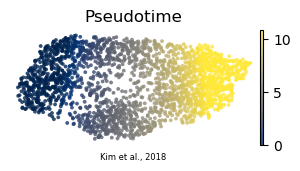

In [8]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Kim et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf | root node =', ROOT_NODE)